# 探索心血管疾病特征之间的关系

| 项目 | 设置 |
|---|---|
| 运行环境 | Python 3.13 + numpy 2.1 + pandas 2.2 + scikit-learn 1.6 + matplotlib 3.10 |
| 数据文件 | `心血管疾病.csv` |
| 输出目录 | `1.csv`、`2.csv`、`1.png` |
| 随机性控制 | `RANDOM_STATE = 42`；`train_test_split`、感知机采样、sklearn 模型全部固定该种子 |

In [ ]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix)

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

# 全局随机种子
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path(r"心血管疾病.csv")
BASE_DIR = Path.cwd()


## 0. 数据清洗和预处理

数据集`心血管疾病.csv`提供了心血管疾病体检数据的横断面样本，**字段含义**如下：

| 字段            | 含义              | 单位 / 取值        |
| ------------- | --------------- | -------------- |
| `id`          | 记录编号（无实际含义）     | 整数             |
| `age`         | 年龄              | **天**          |
| `gender`      | 性别编码            | 1 / 2          |
| `height`      | 身高              | cm             |
| `weight`      | 体重              | kg             |
| `ap_hi`       | 收缩压 SBP         | mmHg           |
| `ap_lo`       | 舒张压 DBP         | mmHg           |
| `cholesterol` | 胆固醇等级           | 1=正常，2=偏高，3=很高 |
| `gluc`        | 血糖等级            | 1=正常，2=偏高，3=很高 |
| `smoke`       | 是否吸烟            | 0=否，1=是        |
| `alco`        | 是否饮酒            | 0=否，1=是        |
| `active`      | 是否规律运动          | 0=否，1=是        |
| `cardio`      | **标签**：是否患心血管疾病 | 0=否，1=是        |

**数据初检**：

- 数据共 70,000 行 × 13 列，**没有缺失值**；
- `id` 唯一，但**去掉 `id` 后仍有 24 行完全相同**（可能是重复录入）；
- 数值范围出现明显不可能的值：`ap_hi` ∈ [-150, 16020]、`ap_lo` ∈ [-70, 11000]、`height` 最小 55 cm、`weight` 最小 10 kg.

In [2]:
df = pd.read_csv(DATA_PATH)
print("原始数据规模: ", df.shape)
print("\n缺失值总数: ", int(df.isna().sum().sum()))
print("完全重复行数: ", int(df.duplicated().sum()))
print("去掉 id 后的重复行数: ", int(df.drop(columns=["id"]).duplicated().sum()))
print("id 是否唯一: ", bool(df["id"].is_unique))

# 分字段的 min / max / mean / std
df.describe().T[["min", "max", "mean", "std"]].round(3)

原始数据规模:  (70000, 13)

缺失值总数:  0
完全重复行数:  0
去掉 id 后的重复行数:  24
id 是否唯一:  True


,min,max,mean,std
id,0.0,99999.0,49972.420,28851.302
age,10798.0,23713.0,19468.866,2467.252
gender,1.0,2.0,1.350,0.477
height,55.0,250.0,164.359,8.210
weight,10.0,200.0,74.206,14.396
ap_hi,-150.0,16020.0,128.817,154.011
ap_lo,-70.0,11000.0,96.630,188.473
cholesterol,1.0,3.0,1.367,0.680
gluc,1.0,3.0,1.226,0.572
smoke,0.0,1.0,0.088,0.283


接下来进行数据清洗。数据清洗依据：

1. 血压特征中，舒张压高于收缩压的样本。
2. 身高特征中，低于 2％ 分位数的样本。
3. 身高特征中，高于 98％ 分位数的样本。
4. 体重特征中，低于 2％ 分位数的样本。
5. 体重特征中，高于 98％ 分位数的样本。

清洗时**保持原始行序**（只删行、不重排、不重置 `id`）。

In [3]:
q_h = np.percentile(df["height"], [2, 98])   # [149. 181.]
q_w = np.percentile(df["weight"], [2, 98])   # [ 50. 110.]
print(f"身高 2%/98% 分位数: {q_h[0]:g} / {q_h[1]:g} cm\n"
      f"体重 2%/98% 分位数: {q_w[0]:g} / {q_w[1]:g} kg")

mask_bp = df["ap_lo"] > df["ap_hi"]                       # 规则 1
mask_h_lo = df["height"] < q_h[0]                         # 规则 2
mask_h_hi = df["height"] > q_h[1]                         # 规则 3
mask_w_lo = df["weight"] < q_w[0]                         # 规则 4
mask_w_hi = df["weight"] > q_w[1]                         # 规则 5
mask_drop = mask_bp | mask_h_lo | mask_h_hi | mask_w_lo | mask_w_hi   # 并集

rule_df = pd.DataFrame({
    "规则": ["r1 ap_lo > ap_hi", "r2 height < 2% 分位", "r3 height > 98% 分位",
             "r4 weight < 2% 分位", "r5 weight > 98% 分位"],
    "判定条件": [f"ap_lo > ap_hi", f"height < {q_h[0]:g}", f"height > {q_h[1]:g}",
                 f"weight < {q_w[0]:g}", f"weight > {q_w[1]:g}"],
    "剔除条数": [int(mask_bp.sum()), int(mask_h_lo.sum()), int(mask_h_hi.sum()),
                 int(mask_w_lo.sum()), int(mask_w_hi.sum())],
})
rule_df["占原始数据(%)"] = (rule_df["剔除条数"] / len(df) * 100).round(2)
print(f"\n五条规则并集共剔除 {int(mask_drop.sum())} 条，占总样本 "
      f"{mask_drop.mean() * 100:.2f}%; 剩余 {int((~mask_drop).sum())} 条。")
rule_df


身高 2%/98% 分位数: 149 / 181 cm
体重 2%/98% 分位数: 50 / 110 kg

五条规则并集共剔除 5500 条，占总样本 7.86%; 剩余 64500 条。


,规则,判定条件,剔除条数,占原始数据(%)
0,r1 ap_lo > ap_hi,ap_lo > ap_hi,1234,1.76
1,r2 height < 2% 分位,height < 149,1196,1.71
2,r3 height > 98% 分位,height > 181,1248,1.78
3,r4 weight < 2% 分位,weight < 50,987,1.41
4,r5 weight > 98% 分位,weight > 110,1247,1.78


In [4]:
df_clean = df.loc[~mask_drop].reset_index(drop=True)
print("清洗后数据规模: ", df_clean.shape)

out_1 = BASE_DIR / "1.csv"
df_clean.to_csv(out_1, index=False, encoding="utf-8-sig")

df_verify = pd.read_csv(out_1)
print("规则复查: 血压违反:",
      int((df_verify["ap_lo"] > df_verify["ap_hi"]).sum()),
      "| 身高越界:",
      int(((df_verify["height"] < q_h[0]) | (df_verify["height"] > q_h[1])).sum()),
      "| 体重越界:",
      int(((df_verify["weight"] < q_w[0]) | (df_verify["weight"] > q_w[1])).sum()))
df_verify.head()

清洗后数据规模:  (64500, 13)
规则复查: 血压违反: 0 | 身高越界: 0 | 体重越界: 0


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


**额外考虑**: 

1. **仍有超过生理范围的血压**：如`ap_lo ≤ 0` 有 20 条; `ap_lo == ap_hi` 有 1 条。部分血压记录不符合常规临床范围。这些记录能通过题目指定的五条规则，但就现实生理条件来看应是错误数据。
2. **24 条重复记录**：含 `id` 的完全重复为 0 条（`id` 唯一），去掉 `id` 后特征完全相同的行有 24 条。本实验保留这些重复数据。

---
## 1. 感知机与逻辑回归

题目要求：

- (1) 取数据集**前 1000 个样本**，按 80%/20% 划分训练集与测试集（`random_state=42`）；
- (2) 先做标准化，再分别用**自己编写的函数**和 **sklearn** 训练**感知机**与**逻辑回归**，比较两者；
- (3) 在测试集上预测，把真实标签与预测结果、以及 4 个模型的混淆矩阵保存到 `2.csv`。

In [5]:
# 取前 1000 个样本，划分训练集/测试集
feature_cols = [c for c in df_clean.columns if c not in ("id", "cardio")]
X = df_clean[feature_cols].to_numpy(dtype=float)
y = df_clean["cardio"].to_numpy(dtype=int)
X_first, y_first = X[:1000], y[:1000]
uniq, cnt = np.unique(y_first, return_counts=True)
print("前 1000 个样本标签分布 =", {int(k): int(v) for k, v in zip(uniq, cnt)})

X_train, X_test, y_train, y_test = train_test_split(
    X_first, y_first, test_size=0.2, random_state=RANDOM_STATE, shuffle=True)
print("训练集:", X_train.shape, "| 测试集:", X_test.shape)
print("训练集类别分布:", np.bincount(y_train), "（索引 0 / 1）")
print("测试集类别分布:", np.bincount(y_test), "（索引 0 / 1）")

前 1000 个样本标签分布 = {0: 492, 1: 508}
训练集: (800, 11) | 测试集: (200, 11)
训练集类别分布: [392 408] （索引 0 / 1）
测试集类别分布: [100 100] （索引 0 / 1）


本数据各特征量纲相差悬殊，数据预处理考虑特征标准化`StandardScaler`: $z=\dfrac{x-\mu}{\sigma}$. 对第 $j$ 个特征，定义
$$\mu_j=\frac1m\sum_{i\in\text{train}}x_{ij},\qquad
\sigma_j=\sqrt{\frac1m\sum_{i\in\text{train}}(x_{ij}-\mu_j)^2},\qquad
z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}.$$

In [6]:
# 标准化
scaler = StandardScaler().fit(X_train)          
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)

根据题目要求，给出**混淆矩阵**计算`evaluate()`，供 4 个模型统一调用：

| | 预测为 0 | 预测为 1 |
|---|---|---|
| **真实为 0** | TN（真负例） | FP（假正例，误诊） |
| **真实为 1** | FN（假负例，漏诊） | TP（真正例） |

`sklearn.metrics.confusion_matrix(y_true, y_pred, labels=[0,1])` 返回数组 [[TN, FP], [FN, TP]]。

In [7]:
def evaluate(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return {"confusion_matrix": cm}

### 1.1 自己编写感知机，与 sklearn Perceptron 对比

**模型。** 感知机是最简单的线性二分类器，对 $d$ 维样本 $x\in\mathbb{R}^d$（本题 $d=11$）输出
$$f(x)=\mathrm{sign}(w\cdot x+b),\qquad
\mathrm{sign}(z)=\begin{cases}+1,&z\ge0,\\-1,&z<0,\end{cases}$$
其中 $w\in\mathbb{R}^d$ 是权重，$b$ 是偏置；$w\cdot x+b=0$ 就是分类超平面。

**标签映射。** 自写实现里把标签 $\{0,1\}$ 映射成 $\{-1,+1\}$：$y_i=2\cdot\text{cardio}_i-1$。

**感知机损失。** 误分类样本 $i$ 满足 $y_i(w\cdot x_i+b)\le 0$。把所有误分类样本记为集合 $M$，感知机准则为
$$L(w,b)=-\sum_{i\in M}y_i(w\cdot x_i+b)\ \ge 0.$$

**梯度与更新。** 对 $L$ 求偏导：$\partial L/\partial w=-\sum_{i\in M}y_i x_i$、$\partial L/\partial b=-\sum_{i\in M}y_i$。每次遇到一个误分类样本就做一次随机梯度下降：
$$\boxed{\;w\leftarrow w+\eta\,y_i x_i,\qquad b\leftarrow b+\eta\,y_i\;}$$
其中 $\eta>0$ 是学习率。

**Novikoff 收敛定理** 给出，若存在单位向量 $w^*$ 与间隔 $\gamma>0$，使得所有样本满足 $y_i(w^*\cdot x_i+b^*)\ge\gamma$，并记 $R=\max_i\|x_i\|$（若把偏置并入增广特征向量，则 $R=\max_i\sqrt{\|x_i\|^2+1}$；为书写简洁，这里按常见做法记 $R=\max_i\|x_i\|$，不影响结论），则感知机最多犯 $\left(\frac{R}{\gamma}\right)^2$ 次错误后收敛。**但医疗数据几乎不可能严格线性可分**，此时感知机会反复更新、**永不收敛**。这里设定最大 epoch 作硬性停止、每轮打乱顺序、监控每轮误分类数；更进一步的 **口袋算法（Pocket）** 保留"历史上误分类最少"的那组 $(w,b)$，而不是返回最后一轮的结果。

In [8]:
# 自编感知机 含 Pocket 改进
class MyPerceptron:
    def __init__(self, eta=0.01, n_epochs=100, random_state=42, use_pocket=True):
        self.eta = eta
        self.n_epochs = n_epochs
        self.random_state = random_state
        self.use_pocket = use_pocket

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel()
        # 标签映射 {0, 1} -> {-1, +1}：y_signed = 2y - 1
        y_signed = np.where(y > 0, 1.0, -1.0)
        n_samples, n_features = X.shape
        self.w_ = np.zeros(n_features)
        self.b_ = 0.0
        rng = np.random.default_rng(self.random_state)   
        self.errors_per_epoch_ = []
        best_errors = n_samples + 1
        best_w, best_b, best_epoch = self.w_.copy(), float(self.b_), 0

        for epoch in range(1, self.n_epochs + 1):
            n_errors = 0
            for i in rng.permutation(n_samples):          # 每个 epoch 打乱样本顺序
                if y_signed[i] * (X[i] @ self.w_ + self.b_) <= 0:   # 误分类样本
                    self.w_ += self.eta * y_signed[i] * X[i]
                    self.b_ += self.eta * y_signed[i]
                    n_errors += 1
            self.errors_per_epoch_.append(n_errors)
            if n_errors < best_errors:                    # Pocket: 保存历史最优权重
                best_errors, best_w, best_b, best_epoch = (
                    n_errors, self.w_.copy(), float(self.b_), epoch)

        self.best_epoch_ = best_epoch
        self.best_errors_ = best_errors
        if self.use_pocket:
            self.w_, self.b_ = best_w, best_b
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

    def predict(self, X):
        # sign(w·x+b) -> {-1,+1}，再映射回 {0,1}
        return (self.decision_function(X) >= 0).astype(int)

pr_scratch = MyPerceptron(eta=0.01, n_epochs=100, random_state=RANDOM_STATE, use_pocket=True)
pr_scratch.fit(X_train_std, y_train)
print(f"训练集准确率: {accuracy_score(y_train, pr_scratch.predict(X_train_std)):.4f}")
pred_pr_scratch = pr_scratch.predict(X_test_std)
res_pr_scratch = evaluate(y_test, pred_pr_scratch)
print("感知机 (自写+Pocket) 混淆矩阵: ", res_pr_scratch["confusion_matrix"].tolist())

训练集准确率: 0.7037
感知机 (自写+Pocket) 混淆矩阵:  [[74, 26], [27, 73]]


In [9]:
# sklearn 感知机
sk_per = Perceptron(random_state=RANDOM_STATE, max_iter=1000, tol=1e-3)
t0 = time.perf_counter()
sk_per.fit(X_train_std, y_train)
t_sk_per = time.perf_counter() - t0

pred_pr_sk = sk_per.predict(X_test_std)
res_pr_sk = evaluate(y_test, pred_pr_sk)
print("感知机 (sklearn) 混淆矩阵: ", res_pr_sk["confusion_matrix"].tolist())
print("\n自写(Pocket) 与 sklearn 感知机的预测一致条数:", int((pred_pr_scratch == pred_pr_sk).sum()), "/ 200")

感知机 (sklearn) 混淆矩阵:  [[79, 21], [37, 63]]

自写(Pocket) 与 sklearn 感知机的预测一致条数: 153 / 200



---
### 1.2 逻辑回归

**模型。** 逻辑回归先做线性打分 $z=w\cdot x+b$，再用 sigmoid 把实数压到 $(0,1)$ 得到概率：
$$\sigma(z)=\frac{1}{1+e^{-z}},\qquad p(y=1\mid x)=\sigma(w\cdot x+b).$$
sigmoid 单调递增、$\sigma(0)=0.5$、$\sigma(-z)=1-\sigma(z)$。

**交叉熵损失函数**：
$$J(w,b)=-\frac1n\sum_{i=1}^n\Bigl[y_i\log p_i+(1-y_i)\log(1-p_i)\Bigr],\qquad p_i=\sigma(w\cdot x_i+b).$$

即逻辑回归的优化目标。通常用梯度下降法求解：

$$\boxed{\;\nabla_w J=\frac1n\sum_{i=1}^n(p_i-y_i)\,x_i=\frac1n X^{\top}(p-y),\qquad
\frac{\partial J}{\partial b}=\frac1n\sum_{i=1}^n(p_i-y_i)\;}$$
其中 $X\in\mathbb{R}^{n\times d}$ 是特征矩阵，$p,y\in\mathbb{R}^n$ 分别是预测概率与真实标签。

梯度下降更新为：

$$w\leftarrow w-\eta\nabla_w J,\qquad b\leftarrow b-\eta\,\frac{\partial J}{\partial b}.$$

标准化之后，特征量级一致，本实验取学习率 $\eta=0.1$、迭代 2000 次，实测收敛。

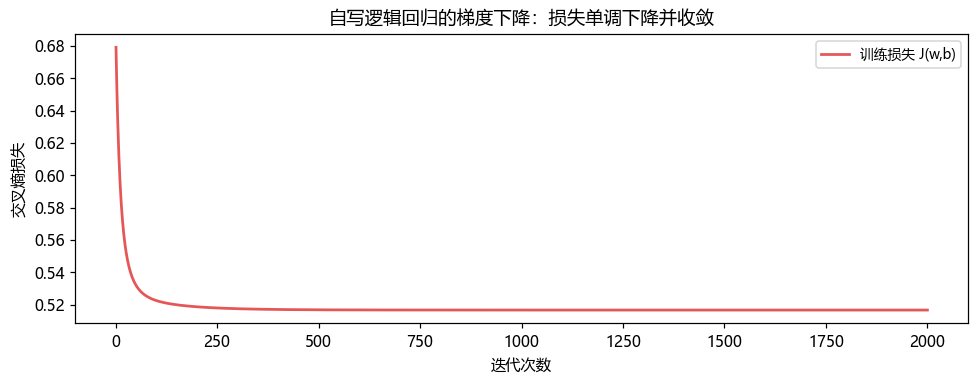

逻辑回归 (自写梯度下降) 混淆矩阵： [[75, 25], [28, 72]]


In [10]:
# 自编逻辑回归 + 批量梯度下降
class MyLogisticRegression:
    def __init__(self, eta=0.1, n_iter=2000):
        self.eta = eta
        self.n_iter = n_iter

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500.0, 500.0)          # 防止 exp 溢出
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        n_samples, n_features = X.shape
        self.w_ = np.zeros(n_features)
        self.b_ = 0.0
        self.loss_history_ = []
        for _ in range(self.n_iter):
            p = self._sigmoid(X @ self.w_ + self.b_)
            grad_w = X.T @ (p - y) / n_samples
            grad_b = np.mean(p - y)
            self.w_ -= self.eta * grad_w
            self.b_ -= self.eta * grad_b
            # 记录更新后的损失
            p = self._sigmoid(X @ self.w_ + self.b_)
            loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
            self.loss_history_.append(loss)
        return self

    def predict_proba(self, X):
        p1 = self._sigmoid(np.asarray(X, dtype=float) @ self.w_ + self.b_)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)   # 阈值 0.5

lr_scratch = MyLogisticRegression(eta=0.1, n_iter=2000)
lr_scratch.fit(X_train_std, y_train)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(np.arange(1, len(lr_scratch.loss_history_) + 1), lr_scratch.loss_history_,
        color="#E45756", lw=1.8, label="训练损失 J(w,b)")
ax.set_xlabel("迭代次数"); ax.set_ylabel("交叉熵损失")
ax.set_title("自写逻辑回归的梯度下降：损失单调下降并收敛")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

pred_lr_scratch = lr_scratch.predict(X_test_std)
res_lr_scratch = evaluate(y_test, pred_lr_scratch)
print("逻辑回归 (自写梯度下降) 混淆矩阵：", res_lr_scratch["confusion_matrix"].tolist())

In [11]:
# sklearn 逻辑回归
sk_lr = LogisticRegression(max_iter=1000)
t0 = time.perf_counter()
sk_lr.fit(X_train_std, y_train)
t_sk_lr = time.perf_counter() - t0

pred_lr_sk = sk_lr.predict(X_test_std)
res_lr_sk = evaluate(y_test, pred_lr_sk)
print("逻辑回归 (sklearn) 混淆矩阵:", res_lr_sk["confusion_matrix"].tolist())
print("\n自写梯度下降 与 sklearn 逻辑回归的预测一致条数:", int((pred_lr_scratch == pred_lr_sk).sum()), "/ 200")

逻辑回归 (sklearn) 混淆矩阵: [[75, 25], [27, 73]]

自写梯度下降 与 sklearn 逻辑回归的预测一致条数: 199 / 200


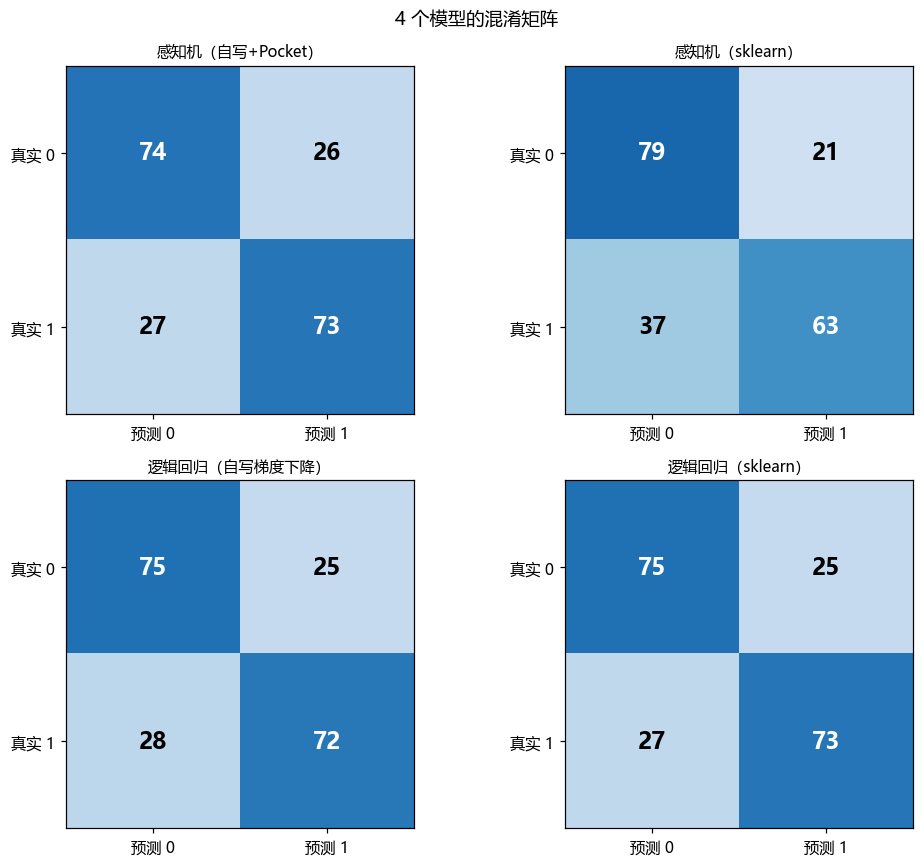

In [12]:
# 4 个模型的结果汇总
results = {
    "感知机（自写+Pocket）": res_pr_scratch,
    "感知机（sklearn）": res_pr_sk,
    "逻辑回归（自写梯度下降）": res_lr_scratch,
    "逻辑回归（sklearn）": res_lr_sk,
}
names = list(results.keys())
fig, axes = plt.subplots(2, 2, figsize=(9.5, 8))
for ax, (name, r) in zip(axes.ravel(), results.items()):
    cm = r["confusion_matrix"]
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=15,
                    color="white" if cm[i, j] > 50 else "black", fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["预测 0", "预测 1"])
    ax.set_yticklabels(["真实 0", "真实 1"])
    ax.set_title(name, fontsize=10)
plt.suptitle("4 个模型的混淆矩阵", fontsize=12)
plt.tight_layout(); plt.show()

In [13]:
# 逻辑回归系数对比
corr_with_cardio_train = [round(float(np.corrcoef(X_train[:, j], y_train)[0, 1]), 4)
                          for j in range(len(feature_cols))]
coef_df = pd.DataFrame({
    "特征": feature_cols,
    "自写逻辑回归系数": lr_scratch.w_.round(4),
    "sklearn 逻辑回归系数": sk_lr.coef_[0].round(4),
    "训练集上与 cardio 的相关系数": corr_with_cardio_train,
})
print("逻辑回归系数（特征已标准化）：")
coef_df

逻辑回归系数（特征已标准化）：


,特征,自写逻辑回归系数,sklearn 逻辑回归系数,训练集上与 cardio 的相关系数
0,age,0.3384,0.3364,0.2383
1,gender,-0.1845,-0.1820,-0.0412
2,height,0.0099,0.0086,-0.0228
3,weight,0.0681,0.0689,0.1329
4,ap_hi,1.1761,1.1523,0.4940
5,ap_lo,0.1904,0.1996,0.3841
6,cholesterol,0.3264,0.3256,0.2928
7,gluc,0.1118,0.1114,0.1531
8,smoke,0.0248,0.0247,-0.0108
9,alco,-0.0349,-0.0351,-0.0161


### 1.3 `2.csv` 的设计与保存

题目要求：把测试集的真实标签与预测结果写入 `2.csv`，**第一列为真实标签、第二列为预测结果**；同时把 4 个模型的混淆矩阵也保存进同一个文件。

In [14]:
# 保存 2.csv: 主表 + 混淆矩阵
pred_df = pd.DataFrame({
    "y_true": y_test,
    "perceptron_scratch": pred_pr_scratch,
    "perceptron_sklearn": pred_pr_sk,
    "logistic_scratch": pred_lr_scratch,
    "logistic_sklearn": pred_lr_sk,
})
csv_path = BASE_DIR / "2.csv"
pred_df.to_csv(csv_path, index=False, encoding="utf-8-sig")   # 主表

# 4 个混淆矩阵

lines = ["",
         "# 混淆矩阵",
         f"# 测试集样本数: {len(y_test)} (0: {int((y_test == 0).sum())}, 1: {int((y_test == 1).sum())})"]
for name, r in results.items():
    cm = r["confusion_matrix"]
    lines += [f"# {name}",
              "# ,pred_0,pred_1",
              f"# true_0,{cm[0, 0]},{cm[0, 1]}",
              f"# true_1,{cm[1, 0]},{cm[1, 1]}"]
with open(csv_path, "a", encoding="utf-8-sig") as f:
    f.write("\n".join(lines) + "\n")

# 读回主表验证
check = pd.read_csv(csv_path, comment="#")
print("\n读回主表规模: ", check.shape)
print(check.head().to_string(index=False))


读回主表规模:  (200, 5)
 y_true  perceptron_scratch  perceptron_sklearn  logistic_scratch  logistic_sklearn
      0                   0                   0                 0                 0
      0                   0                   0                 0                 0
      1                   0                   0                 0                 0
      0                   0                   0                 0                 0
      1                   1                   1                 1                 1


---
## 2. 抽烟与不抽烟人数占比饼图

清洗后 N = 64500：smoke=0 有 58927 人（91.36%），smoke=1 有 5573 人（8.64%）


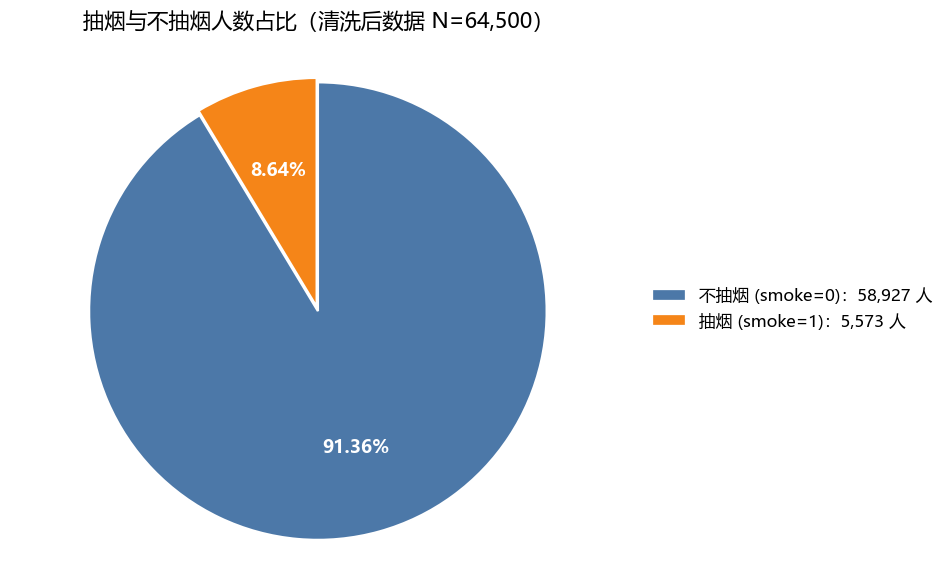

In [15]:
# 绘制饼图并保存为 1.png
smoke_counts = df_clean["smoke"].value_counts().sort_index()
n0, n1 = int(smoke_counts[0]), int(smoke_counts[1])
N = n0 + n1
print(f"清洗后 N = {N}：smoke=0 有 {n0} 人（{n0 / N * 100:.2f}%），"
      f"smoke=1 有 {n1} 人（{n1 / N * 100:.2f}%）")

fig, ax = plt.subplots(figsize=(7.2, 6.0))
sizes = [n0, n1]                                  # 分别对应 smoke=0 / smoke=1
colors = ["#4C78A8", "#F58518"]
labels = [f"不抽烟 (smoke=0)：{n0:,} 人", f"抽烟 (smoke=1)：{n1:,} 人"]

wedges, _, autotexts = ax.pie(
    sizes,
    colors=colors,
    autopct="%1.2f%%",
    startangle=90,
    counterclock=False,
    explode=(0, 0.02),
    pctdistance=0.62,
    textprops={"fontsize": 12},
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)
for at in autotexts:
    at.set_color("white"); at.set_fontweight("bold")

ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(1.02, 0.5),
          frameon=False, fontsize=11)
ax.set_title("抽烟与不抽烟人数占比（清洗后数据 N=%s）" % f"{N:,}", fontsize=14, pad=18)
ax.axis("equal")

out_png = BASE_DIR / "1.png"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()